In [ ]:
from sklearn.datasets import fetch_openml

# Charger MNIST
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)

# Normaliser [0,255] → [0,1]
X = X / 255.0

# Séparer train/test (les 60K premiers pour train et 10K pour test)
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000].astype(int), y[60000:].astype(int)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

# Reshape pour CNN (60000, 28, 28, 1)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)
print(X_train_cnn.shape)
print(X_test_cnn.shape)

(60000, 784)
(10000, 784)
(60000,)
(10000,)
(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Construction du modèle
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Entraînement
history = model.fit(X_train_cnn, y_train, epochs=10, validation_split=0.1)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.9346 - loss: 0.2142 - val_accuracy: 0.9857 - val_loss: 0.0520
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9763 - loss: 0.0797 - val_accuracy: 0.9890 - val_loss: 0.0381
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9823 - loss: 0.0577 - val_accuracy: 0.9900 - val_loss: 0.0360
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9853 - loss: 0.0472 - val_accuracy: 0.9917 - val_loss: 0.0325
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9879 - loss: 0.0402 - val_accuracy: 0.9907 - val_loss: 0.0323
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9894 - loss: 0.0333 - val_accuracy: 0.9922 - val_loss: 0.0314
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9913 - loss: 0.0283 - val_accuracy: 0.9910 - val_loss: 0.0348
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9924 - loss: 0.0250 -

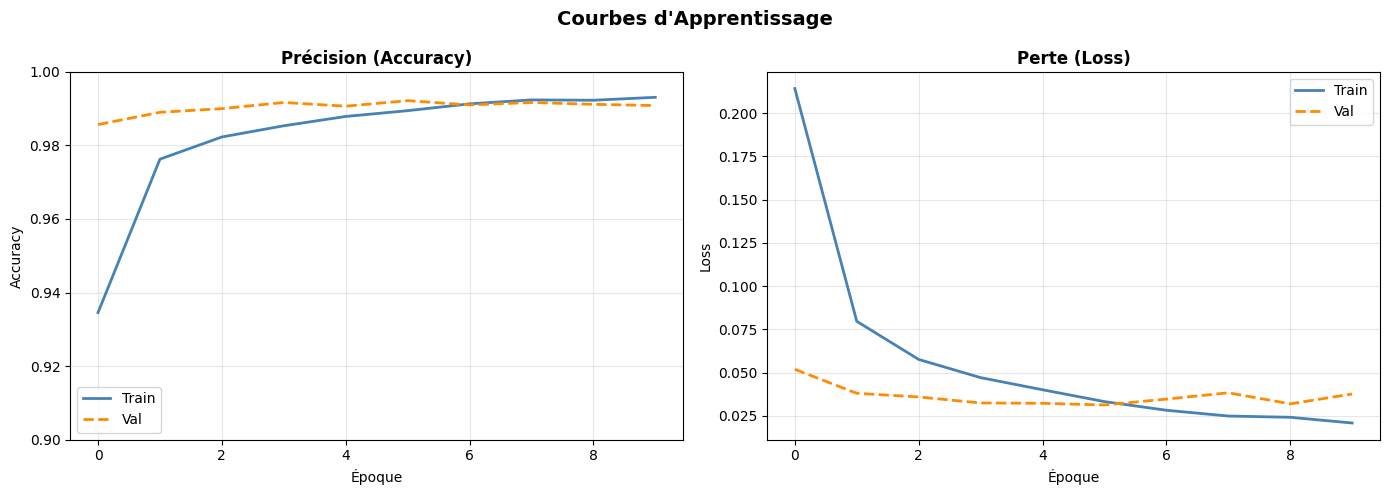

In [24]:
import matplotlib.pyplot as plt

# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Courbe de précision
axes[0].plot(history.history['accuracy'],     label='Train', color='steelblue',  linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Val',   color='darkorange', linewidth=2, linestyle='--')
axes[0].set_title('Précision (Accuracy)', fontweight='bold')
axes[0].set_xlabel('Époque')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].set_ylim([0.9, 1.0])
axes[0].grid(True, alpha=0.3)

# Courbe de perte
axes[1].plot(history.history['loss'],     label='Train', color='steelblue',  linewidth=2)
axes[1].plot(history.history['val_loss'], label='Val',   color='darkorange', linewidth=2, linestyle='--')
axes[1].set_title('Perte (Loss)', fontweight='bold')
axes[1].set_xlabel('Époque')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("Courbes d'Apprentissage", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [25]:
# Evaluation sur l'ensemble de test
test_loss, test_acc = model.evaluate(X_test_cnn, y_test, verbose=0)

print(f"Perte (Loss) : {test_loss:.4f}  =>  {test_loss*100:.2f}%")
print(f"Précision (Acc) : {test_acc:.4f}  =>  {test_acc*100:.2f}%")
print(f"Erreurs sur 10 000 : {int((1 - test_acc) * 10000)}")

Perte (Loss) : 0.0303  =>  3.03%
Précision (Acc) : 0.9916  =>  99.16%
Erreurs sur 10 000 : 84


In [26]:
import numpy as np
from sklearn.metrics import classification_report

# Rapport de classification complet
y_pred_proba = model.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)   # Classe prédite = indice max

print(classification_report(y_test, y_pred, target_names=[f"Chiffre {i}" for i in range(10)]))

              precision    recall  f1-score   support

   Chiffre 0       0.99      0.99      0.99       980
   Chiffre 1       1.00      0.99      0.99      1135
   Chiffre 2       0.99      0.99      0.99      1032
   Chiffre 3       0.99      1.00      0.99      1010
   Chiffre 4       0.99      0.99      0.99       982
   Chiffre 5       0.98      0.99      0.99       892
   Chiffre 6       0.99      0.99      0.99       958
   Chiffre 7       0.99      0.99      0.99      1028
   Chiffre 8       0.99      0.99      0.99       974
   Chiffre 9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



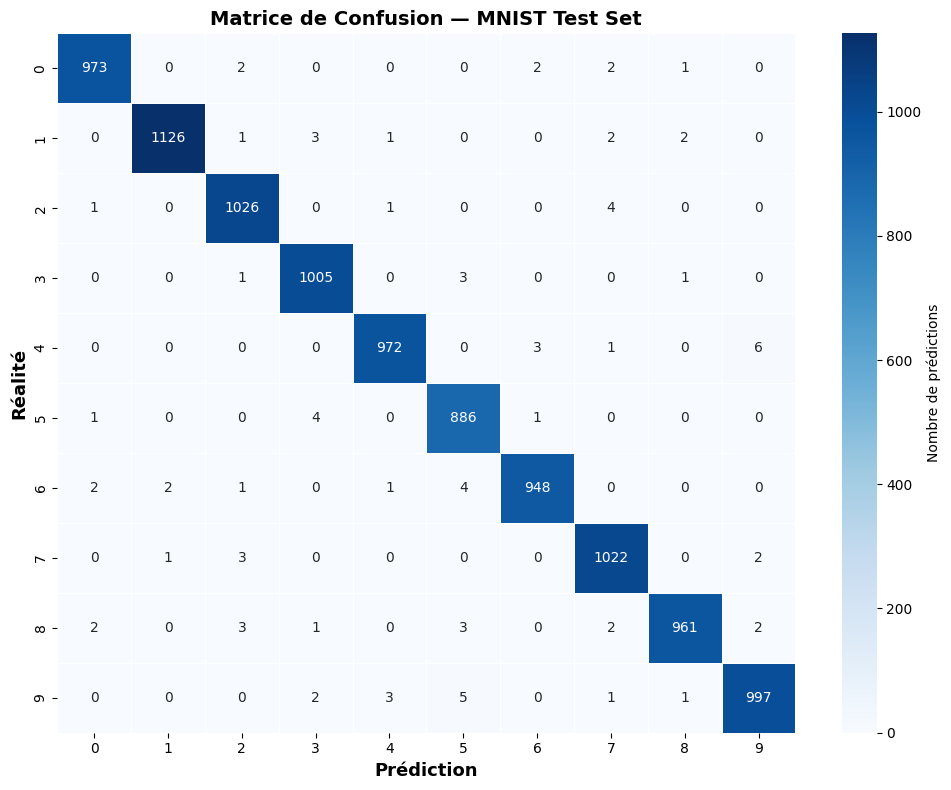


Top 5 des confusions les plus fréquentes :
   Réel=4 prédit comme 9 : 6 fois
   Réel=9 prédit comme 5 : 5 fois
   Réel=2 prédit comme 7 : 4 fois
   Réel=5 prédit comme 3 : 4 fois
   Réel=6 prédit comme 5 : 4 fois


In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10),
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Nombre de prédictions'})
ax.set_xlabel('Prédiction', fontsize=13, fontweight='bold')
ax.set_ylabel('Réalité', fontsize=13, fontweight='bold')
ax.set_title('Matrice de Confusion — MNIST Test Set', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Afficher les confusions les plus fréquentes
print("\nTop 5 des confusions les plus fréquentes :")
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
for _ in range(5):
    idx = np.unravel_index(cm_no_diag.argmax(), cm_no_diag.shape)
    print(f"   Réel={idx[0]} prédit comme {idx[1]} : {cm_no_diag[idx]} fois")
    cm_no_diag[idx] = 0

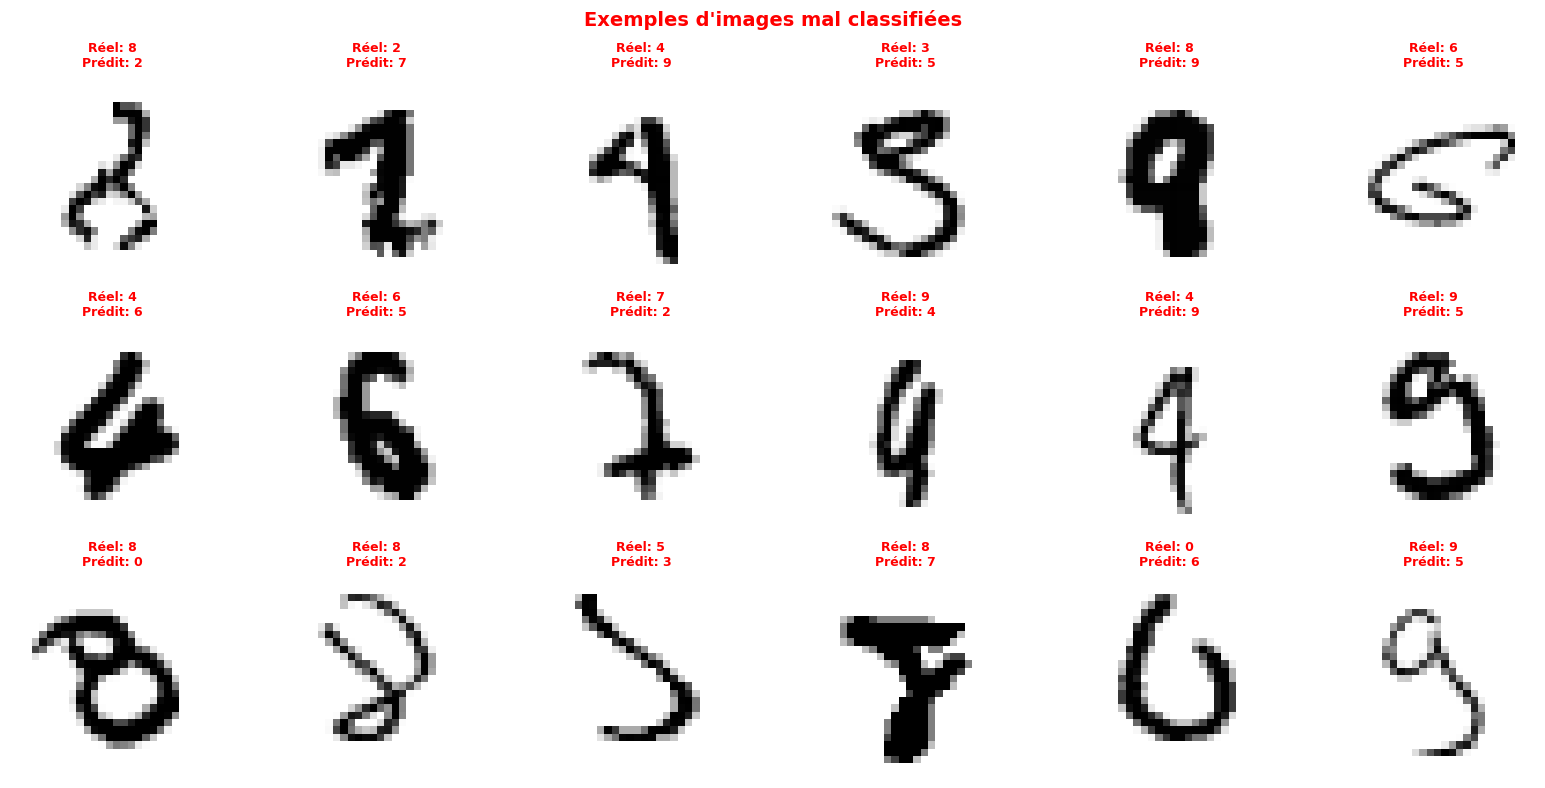

In [28]:
# Exemples d'erreurs de classification
errors = np.where(y_pred != y_test)[0]

fig, axes = plt.subplots(3, 6, figsize=(16, 8))
fig.suptitle("Exemples d'images mal classifiées", fontsize=14, fontweight='bold', color='red')

for i, idx in enumerate(errors[:18]):
    ax = axes[i // 6, i % 6]
    ax.imshow(X_test_cnn[idx], cmap='gray_r')
    ax.set_title(f"Réel: {y_test[idx]}\nPrédit: {y_pred[idx]}",
                 color='red', fontsize=9, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [29]:
# Sauvegarde au format natif Keras (.keras)
model.save('mnist_mlp_model.keras')
print("✅ Modèle sauvegardé dans 'mnist_mlp_model.keras'")

✅ Modèle sauvegardé dans 'mnist_mlp_model.keras'
